<a href="https://colab.research.google.com/github/MilkySon/RL_carracing_competition/blob/main/colab_quickstartE3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CarRacing RL Competition — Colab Quickstart

런타임 > 런타임 유형 변경 > **T4 GPU** 를 선택한 뒤 실행하세요.
학습 결과(`RUN_DIR`)는 Google Drive에 저장되므로 세션이 끊겨도 `--resume`으로 이어갈 수 있습니다.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. 코드 준비
`carracing_competition` 폴더를 Drive에 올려 두었다고 가정합니다. 경로를 맞게 수정하세요.

In [2]:
%cd "/content/drive/MyDrive/261029carracing_competition"
!pip install -q swig
!pip install -q -r requirements.txt

/content/drive/MyDrive/261029carracing_competition


## 2. 학습
처음 실행할 때와 이어서 실행할 때 모두 같은 셀을 쓰면 됩니다 (`--resume`은 체크포인트가 없으면 새로 시작).

In [3]:
AGENT = 'dqn'
SEED = 0
RUN_DIR = f'runs/{AGENT}_s{SEED}'

# !python train.py --agent {AGENT} --seed {SEED} --run-dir {RUN_DIR} --resume
# !python train.py --experiment E1 --agent dqn --seed 0 --budget 300000 --frame-skip 2 --run-dir runs/E1_dqn
# !python train.py --experiment E2 --agent dqn --seed 0 --budget 300000 --n-stack 8 --run-dir runs/E2_dqn
!python train.py --experiment E3 --agent dqn --seed 0 --budget 300000 --image-size 84 --run-dir runs/E3_dqn
# !python train.py --experiment E8 --agent dqn --seed 0 --budget 300000 --cfg eps_end=0.03 --run-dir runs/E8_dqn


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
agent=dqn action=discrete device=cuda budget=300,000 frames
[    1,000] ep    1 return   -34.6 (97 fps) 
[    2,000] ep    2 return   -58.6 (102 fps) 
[    3,000] ep    3 return   -36.8 (106 fps) 
[    4,000] ep    4 return   -60.9 (110 fps) 
[    5,000] ep    5 return   -34.2 (112 fps) 
[    6,000] ep    6 return   -16.3 (114 fps) 
[    7,000] ep    7 return   -36.2 (115 fps) 
[    8,000] ep    8 return   -31.7 (116 fps) 
[    9,000] ep    9 return   -37.3 (117 fps) 
[   10,000] ep   10 return   -58.9 (118 fps) 
[   11,000] ep   11 return   -32.0 (119 fps) 
[   12,000] ep   12 return   -70.5 (119 fps) 
[   13,000] ep   13 retu

## 3. 학습 곡선

In [4]:

RUN_DIR = 'runs/E3_dqn'

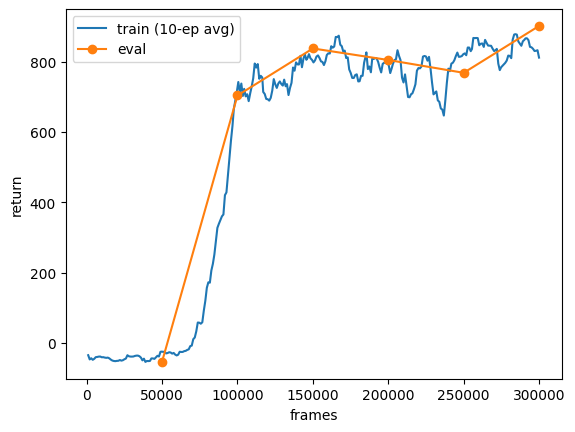

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

import csv
# 앞의 5개 열(frames, episode, return, length, time)만 사용 -> 학습 지표 열 수가 달라도 읽힘
with open(f'{RUN_DIR}/train.csv') as f:
    rows = list(csv.reader(f))
train = pd.DataFrame([r[:5] for r in rows[1:]], columns=rows[0][:5]).astype({'frames': int, 'return': float})
ev = pd.read_csv(f'{RUN_DIR}/eval.csv')
plt.plot(train.frames, train['return'].rolling(10, min_periods=1).mean(), label='train (10-ep avg)')
plt.plot(ev.frames, ev.score, 'o-', label='eval')
plt.xlabel('frames'); plt.ylabel('return'); plt.legend(); plt.show()

## 4. 평가 및 주행 영상

In [10]:
!python evaluate.py --ckpt {RUN_DIR}/best.pt --seeds 1000-1009 --video videos/{AGENT}

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
/usr/local/lib/python3.13/dist-packages/gymnasium/wrappers/rendering.py:293: UserWarning: WARN: Overwriting existing videos at /content/drive/MyDrive/261029carracing_competition/videos/dqn folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(
seed 1000:    916.4
seed 1001:    907.3
seed 1002:    917.6
seed 1003:    915.5
seed 1004:    896.6
seed 1005:    875.5
seed 1006:    922.0
seed 1007:    896.8
seed 1008:    884.2
seed 1009:    837.0
SCORE (mean over 10 tracks): 896.9 ± 24.7


In [7]:
import glob
from IPython.display import Video
Video(sorted(glob.glob(f'videos/{AGENT}/*.mp4'))[0], embed=True, width=400)

## 5. 리더보드 제출 파일 만들기
`TEAM_NAME`을 본인 팀 이름으로 바꾸세요 (파일 이름이 팀 이름으로 시작해야 합니다). 행동 일치율이 95% 미만이면 제출하지 마세요.

In [11]:
# 성능 확인용
TEAM_NAME = 'WhatsHappeningE3'
!python export.py --ckpt {RUN_DIR}/best.pt --out "{TEAM_NAME}.onnx"
!python check_submission.py --onnx "{TEAM_NAME}.onnx"

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
saved WhatsHappeningE3.onnx  (continuous=False, frame_skip=4, n_stack=4)
행동 일치율: 98.1% (209 steps)
참고: 95% 이상이면 정상입니다. Q값/확률이 거의 같은 행동 사이에서 미세한 계산 오차로 선택이 갈릴 수 있습니다.
제출 전 확인: python check_submission.py --onnx WhatsHappeningE3.onnx
/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
설정: {'continuous': False, 'frame_skip':

In [ ]:
# 찐제출용
TEAM_NAME = 'MyTeam'
!python export.py --ckpt {RUN_DIR}/best.pt --out "{TEAM_NAME}.onnx"
!python check_submission.py --onnx "{TEAM_NAME}.onnx"